# Model masking comparison

Compares every masked-video run against the **manually annotated label video** (the reference = **100%**).

**Primary metric — `masks_vs_label_%`**: number of masks each model draws relative to the label's total. This measures *how many faces are caught* regardless of mask size, so small-box detectors (e.g. yolov7-tiny head) are not penalised the way pixel-IoU would penalise them. Label = 100% by definition.

Also reported: absolute counts (`avg_masks/frame`, `total_masks`), `count_MAE` (avg per-frame difference vs label), and speed (`avg_ms/frame`, `fps`). Pixel IoU/coverage are kept in the detailed table only, as secondary context.

All runs are now letterboxed **portrait 480×720** (the `detect`/`mediapipe` runs were re-exported with the studio `normalize` step), so framing is consistent.

Run with the **conda `base`** kernel (`~/anaconda3`).

In [1]:
%matplotlib inline
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analysis_lib as al

DATA_ROOT = al.DATA_ROOT  # '/home/gustavo-luz/code/mascaramento'

# Use the PORTRAIT re-run of detect/mediapipe; drop the old landscape folder.
all_folders = sorted(d for d in glob.glob(os.path.join(DATA_ROOT, '*'))
                     if os.path.isdir(d) and 'video' in os.path.basename(d).lower())
FOLDERS = [f for f in all_folders
           if os.path.basename(f) != 'video_yolonotrack_mediapipe']  # exclude landscape
print('DATA_ROOT =', DATA_ROOT)
for f in FOLDERS:
    print('  ', os.path.basename(f))

DATA_ROOT = /home/gustavo-luz/code/mascaramento
   video_label
   video_yolonotrack_mediapipe_portrait
   video_yolov7tiny
   video_yolov8n
   videos_yolopose


In [2]:
summary, per_frame, runs, label_name = al.build_summary(DATA_ROOT, folders=FOLDERS)
print('Label (100% reference):', label_name)
summary

Label (100% reference): video_label/yolo26m-pose


,model,weights,stage,is_label,resolution,frames,avg_masks/frame,total_masks,avg_ms/frame,median_ms,fps,IoU,coverage_%,precision_%,count_MAE,mean_pred_px,mean_gt_px,total_pred_px,masks_vs_label_%
0,video_label/yolo26m-pose,manual,manual,True,480x720,188,9.888,1859,13.51,NaN,74.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
1,video_yolov7tiny/yolov7_tiny_head_0.752,yolov7_tiny_head_0.752_post_480x640.onnx,track,False,480x720,188,8.468,1592,78.46,73.05,12.74,0.1292,13.26,85.63,1.867,11976.0,75829.0,2251628.0,85.6
2,video_yolonotrack_mediapipe_portrait/detect_yo...,?,?,False,480x720,188,7.723,1452,256.01,256.97,3.91,0.9040,95.06,94.80,2.239,76253.0,75829.0,14335692.0,78.1
3,videos_yolopose/yolo26m-pose,yolo26m-pose.pt,track,False,480x720,188,6.654,1251,498.85,480.50,2.00,0.9587,96.88,98.90,3.234,74582.0,75829.0,14021426.0,67.3
4,videos_yolopose/yolo11x-pose,yolo11x-pose.pt,track,False,480x720,188,6.144,1155,1468.64,1377.30,0.68,0.8947,93.10,95.74,3.745,74506.0,75829.0,14007169.0,62.1
5,video_yolonotrack_mediapipe_portrait/mediapipe,?,?,False,480x720,188,1.144,215,6.39,6.30,156.44,0.0572,5.89,67.80,8.745,6415.0,75829.0,1206020.0,11.6


## Summary table

Lead columns are count-based (the metric of interest). Pixel `IoU`/`coverage_%` are shown last as secondary context. `masks_vs_label_%` shaded red→green (0→100); green = fastest / lowest count error.

In [3]:
cols = ['model', 'resolution', 'masks_vs_label_%', 'total_masks', 'avg_masks/frame',
        'count_MAE', 'avg_ms/frame', 'fps', 'coverage_%', 'IoU']
tbl = summary[[c for c in cols if c in summary.columns]].copy()

def _style(df):
    return (df.style
              .format({'masks_vs_label_%': '{:.1f}', 'avg_masks/frame': '{:.2f}',
                       'count_MAE': '{:.2f}', 'avg_ms/frame': '{:.1f}', 'fps': '{:.1f}',
                       'coverage_%': '{:.1f}', 'IoU': '{:.3f}'}, na_rep='—')
              .background_gradient(subset=['masks_vs_label_%'], cmap='RdYlGn', vmin=0, vmax=100)
              .highlight_max(subset=['fps'], color='#1b5e20')
              .highlight_min(subset=['count_MAE', 'avg_ms/frame'], color='#1b5e20'))
try:
    display(_style(tbl))
except Exception:
    print(tbl.to_string(index=False))

,model,resolution,masks_vs_label_%,total_masks,avg_masks/frame,count_MAE,avg_ms/frame,fps,coverage_%,IoU
0,video_label/yolo26m-pose,480x720,100.0,1859,9.89,—,13.5,74.0,—,—
1,video_yolov7tiny/yolov7_tiny_head_0.752,480x720,85.6,1592,8.47,1.87,78.5,12.7,13.3,0.129
2,video_yolonotrack_mediapipe_portrait/detect_yolo11m,480x720,78.1,1452,7.72,2.24,256.0,3.9,95.1,0.904
3,videos_yolopose/yolo26m-pose,480x720,67.3,1251,6.65,3.23,498.9,2.0,96.9,0.959
4,videos_yolopose/yolo11x-pose,480x720,62.1,1155,6.14,3.75,1468.6,0.7,93.1,0.895
5,video_yolonotrack_mediapipe_portrait/mediapipe,480x720,11.6,215,1.14,8.74,6.4,156.4,5.9,0.057


## Masks vs label total (primary)

How many masks each model draws as a % of the label's total. 100% = same count as the manual annotation.

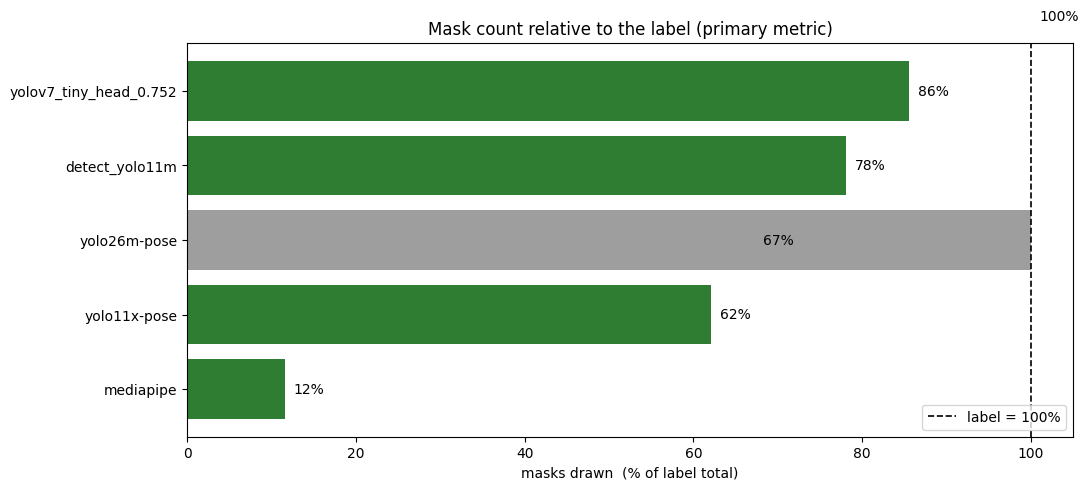

In [4]:
d = summary.copy()
d['short'] = d['model'].str.split('/').str[-1]
d = d.sort_values('masks_vs_label_%')
colors = ['#9e9e9e' if lab else '#2e7d32' for lab in d['is_label']]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(d['short'], d['masks_vs_label_%'], color=colors)
ax.axvline(100, color='k', ls='--', lw=1.2, label='label = 100%')
for i, v in enumerate(d['masks_vs_label_%']):
    ax.text(v + 1, i, f'{v:.0f}%', va='center', fontsize=10)
ax.set_xlabel('masks drawn  (% of label total)')
ax.set_title('Mask count relative to the label (primary metric)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## Masks per frame (absolute) vs label

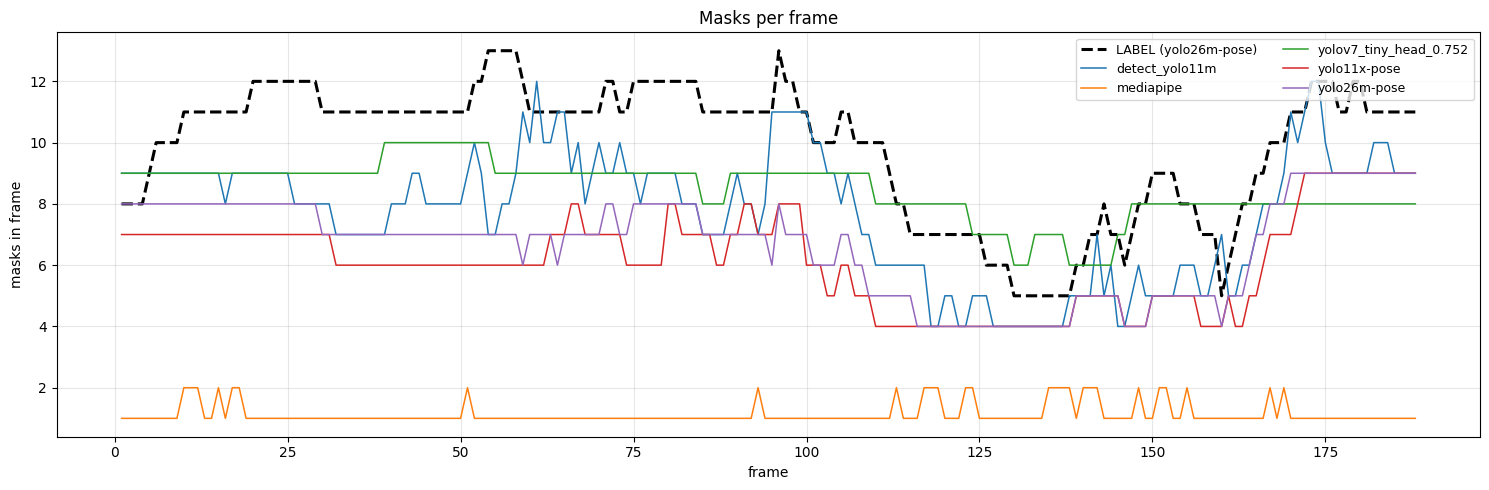

In [5]:
fig, ax = plt.subplots(figsize=(15, 5))
label_df = al.load_run(runs[label_name])
ax.plot(label_df['frame'], label_df['bboxes'].apply(len), 'k--', lw=2.2,
        label=f'LABEL ({label_name.split("/")[-1]})')
for name, pf in per_frame.items():
    ax.plot(pf['frame'], pf['count_pred'], lw=1.1, label=name.split('/')[-1])
ax.set_xlabel('frame'); ax.set_ylabel('masks in frame')
ax.set_title('Masks per frame'); ax.legend(ncol=2, fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Speed vs mask count

Top-right = catches as many faces as the label **and** runs fast. Bubble size ∝ avg masks/frame.

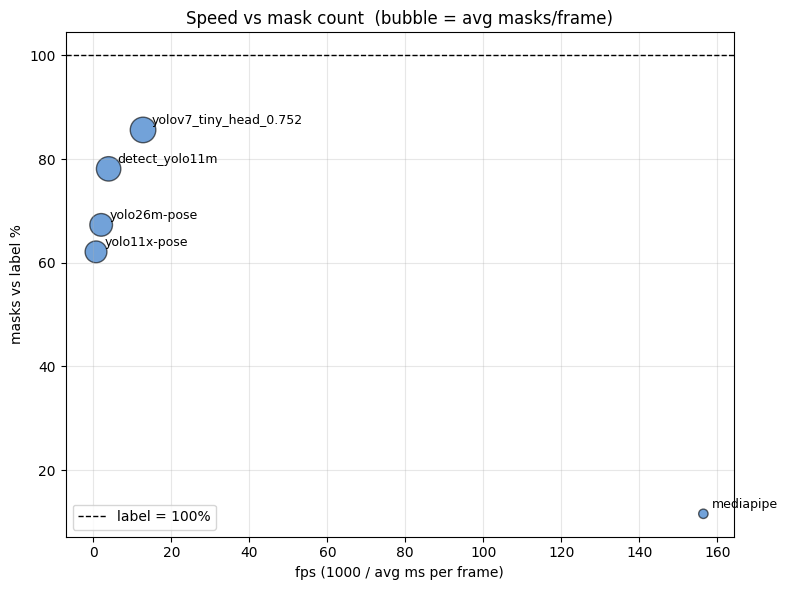

In [6]:
d = summary[~summary['is_label']].dropna(subset=['fps']).copy()
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(d['fps'], d['masks_vs_label_%'], s=d['avg_masks/frame'] * 40,
           c='#1565c0', alpha=0.6, edgecolors='k')
for _, r in d.iterrows():
    ax.annotate(r['model'].split('/')[-1], (r['fps'], r['masks_vs_label_%']),
                xytext=(6, 4), textcoords='offset points', fontsize=9)
ax.axhline(100, color='k', ls='--', lw=1, label='label = 100%')
ax.set_xlabel('fps (1000 / avg ms per frame)')
ax.set_ylabel('masks vs label %')
ax.set_title('Speed vs mask count  (bubble = avg masks/frame)')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Qualitative side-by-side (black letterbox cropped)

One labelled row per timestamp. The black padding around the image is trimmed automatically. Edit `TIMES` (seconds).

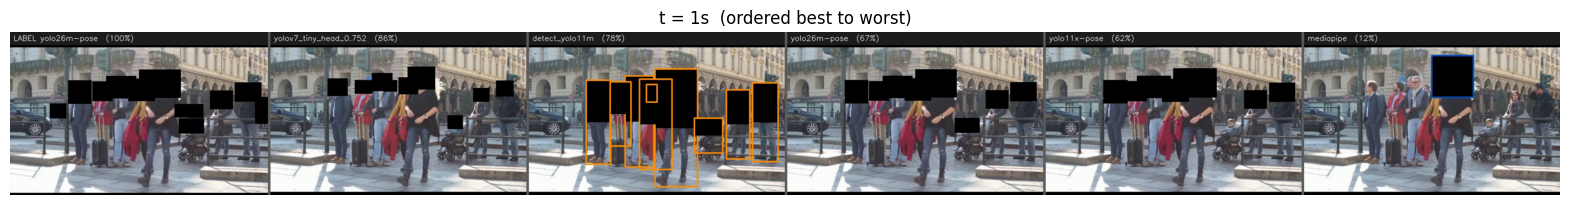

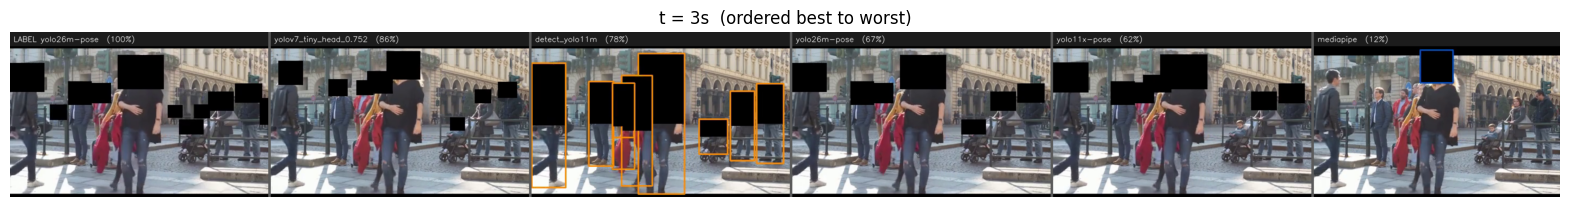

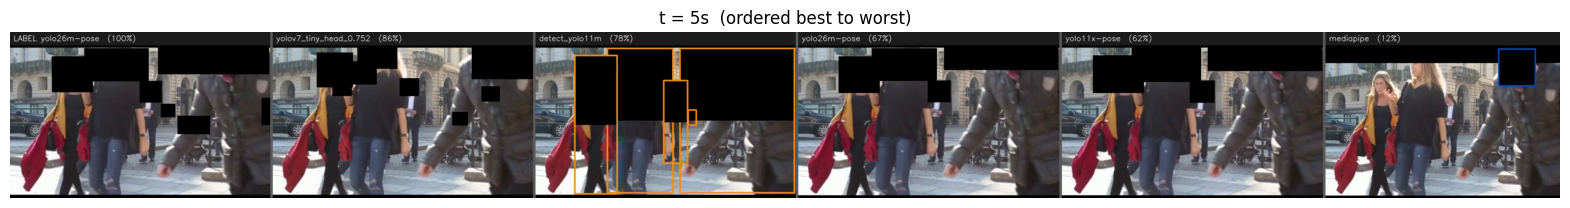

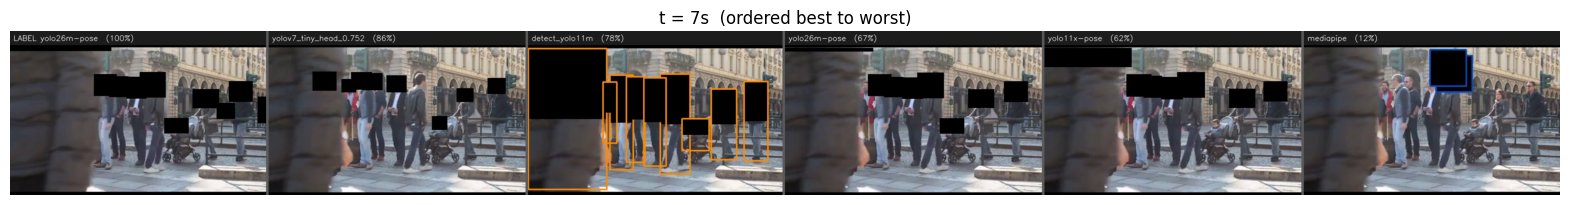

In [7]:
import importlib, qualitative_compare as qc
importlib.reload(qc)
import cv2

TIMES = [1.0, 3.0, 5.0, 7.0]
# Ranked best->worst by accuracy (masks vs label %), label first; each tile
# titled with model name + accuracy. Same view used for the paper figure.
ranked = qc.ranked_runs(al.discover_runs(DATA_ROOT, folders=FOLDERS), best_first=True)
for t in TIMES:
    tiles = []
    for r, acc in ranked:
        fr = qc.grab_frame(r.video, t, r.fps)
        if fr is None:
            continue
        tiles.append(qc.labelled_tile(fr, qc.tile_title(r, acc), height=360))
    row = qc.hstack_pad(tiles)
    plt.figure(figsize=(20, 4.5))
    plt.imshow(cv2.cvtColor(row, cv2.COLOR_BGR2RGB)); plt.axis('off')
    plt.title(f't = {t:g}s  (ordered best to worst)'); plt.show()

Export to disk from a terminal:

```bash
~/anaconda3/bin/python qualitative_compare.py --times 1,3,5,7 --out qualitative/ --grid
```